<a href="https://colab.research.google.com/github/anvithagcs24-stack/BISLAB/blob/main/1WN24CS047_BIS_WEEK4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

# ==========================================
# 1. DEFINE PROBLEM & PARAMETERS
# ==========================================
# Locations: 0: Warehouse, 1: Store A, 2: Store B, 3: Store C
locations = ["Warehouse", "Store A", "Store B", "Store C"]
num_nodes = len(locations)

# Distance matrix (in km)
dist_matrix = np.array([
    [0,  10, 15, 20],  # Warehouse
    [10,  0, 35, 25],  # Store A
    [15, 35,  0, 30],  # Store B
    [20, 25, 30,  0]   # Store C
], dtype=float)

# Heuristic information eta = 1 / distance (avoid division by zero on diagonal)
with np.errstate(divide='ignore'):
    eta = np.where(dist_matrix != 0, 1.0 / dist_matrix, 0)

# ACO Parameters
num_ants = 10
num_iterations = 50
alpha = 1.0      # Pheromone importance
beta = 2.0       # Distance preference importance
rho = 0.1        # Pheromone evaporation rate
Q = 100.0        # Pheromone deposit constant

# Initialize pheromone matrix with a small positive value
pheromones = np.ones((num_nodes, num_nodes)) * 0.1


# ==========================================
# 2. ANT COLONY OPTIMIZATION LOOP
# ==========================================
best_distance = float('inf')
best_path = None

for iteration in range(num_iterations):
    all_paths = []
    all_distances = []

    for ant in range(num_ants):
        # Start every ant at the Warehouse (node 0)
        path = [0]
        visited = set(path)

        # Construct tour step-by-step
        while len(path) < num_nodes:
            current = path[-1]
            unvisited = [node for node in range(num_nodes) if node not in visited]

            # Calculate selection probabilities for unvisited neighbors
            probabilities = []
            for neighbor in unvisited:
                tau = pheromones[current][neighbor] ** alpha
                eta_val = eta[current][neighbor] ** beta
                probabilities.append(tau * eta_val)

            probabilities = np.array(probabilities)
            probabilities /= probabilities.sum()  # Normalize to sum to 1

            # Choose next node based on probability distribution
            next_node = np.random.choice(unvisited, p=probabilities)
            path.append(next_node)
            visited.add(next_node)

        # Complete loop back to Warehouse (node 0)
        path.append(0)

        # Calculate total path length
        distance = sum(dist_matrix[path[i]][path[i + 1]] for i in range(num_nodes))

        all_paths.append(path)
        all_distances.append(distance)

        # Track global best route
        if distance < best_distance:
            best_distance = distance
            best_path = path

    # --- Pheromone Update Phase ---
    # 1. Evaporation
    pheromones *= (1 - rho)

    # 2. Pheromone Deposit by all ants
    for path, distance in zip(all_paths, all_distances):
        deposit = Q / distance
        for i in range(num_nodes):
            u, v = path[i], path[i + 1]
            pheromones[u][v] += deposit
            pheromones[v][u] += deposit  # Symmetric TSP

# ==========================================
# 3. OUTPUT RESULTS
# ==========================================
named_path = [locations[node] for node in best_path]

print("--- ACO Search Complete ---")
print(f"Shortest Total Distance: {best_distance:.2f} km")
print("Optimal Route:")
print(" -> ".join(named_path))

--- ACO Search Complete ---
Shortest Total Distance: 80.00 km
Optimal Route:
Warehouse -> Store A -> Store C -> Store B -> Warehouse


Running Ant Colony Optimization...
Iteration 10/50 | Best Distance: 296.25 meters
Iteration 20/50 | Best Distance: 296.25 meters
Iteration 30/50 | Best Distance: 296.25 meters
Iteration 40/50 | Best Distance: 296.25 meters
Iteration 50/50 | Best Distance: 296.25 meters

=== OPTIMIZATION COMPLETE ===
Best Optimized Route Order: 0 -> 4 -> 1 -> 6 -> 10 -> 9 -> 7 -> 2 -> 8 -> 3 -> 5 -> 0
Minimum Total Distance: 296.25 meters


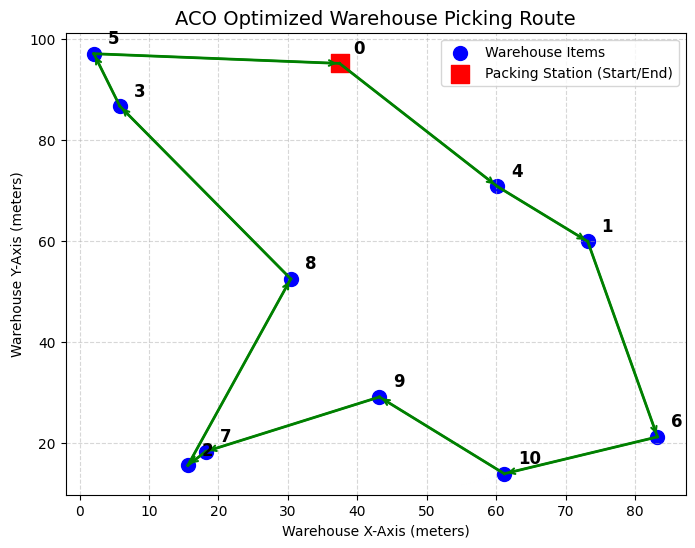

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

# ==========================================
# 1. SETUP THE PROBLEM (Warehouse Layout)
# ==========================================
# Let's say the packing station is at (0,0), and we have 10 item locations to pick up.
np.random.seed(42) # For reproducible results
num_items = 11 # 1 Packing station + 10 Item locations

# Generate random X, Y coordinates for the items in the warehouse (meters)
# Node 0 will be the packing station where the picker starts and ends.
locations = np.random.rand(num_items, 2) * 100

# Calculate the distance matrix (distance between every pair of locations)
distance_matrix = cdist(locations, locations, metric='euclidean')
# Prevent division by zero for visibility calculations
distance_matrix[distance_matrix == 0] = 1e-10

# ==========================================
# 2. ACO ALGORITHM HYPERPARAMETERS
# ==========================================
num_ants = 15          # Number of virtual ants per iteration
num_iterations = 50    # How many times the ants will hunt for paths
alpha = 1.0            # Pheromone importance factor
beta = 2.0             # Distance shorthand/visibility importance factor
evaporation_rate = 0.5 # How fast pheromones fade away (50% each iteration)
Q = 100                # Pheromone deposit constant

# Initialize pheromones equally on all paths
pheromones = np.ones((num_items, num_items))
# Visibility is the inverse of distance (shorter paths look more attractive)
visibility = 1.0 / distance_matrix

best_distance = float('inf')
best_route = []

# ==========================================
# 3. CORE ACO LOOP
# ==========================================
print("Running Ant Colony Optimization...")

for iteration in range(num_iterations):
    all_ant_routes = []
    all_ant_distances = []

    for ant in range(num_ants):
        # Every ant starts at the Packing Station (Node 0)
        current_node = 0
        visited = [current_node]
        unvisited = list(range(1, num_items))

        while unvisited:
            # Calculate the transition probabilities for the next unvisited nodes
            pheromone_vals = pheromones[current_node, unvisited] ** alpha
            visibility_vals = visibility[current_node, unvisited] ** beta
            probabilities = pheromone_vals * visibility_vals

            # Normalize probabilities so they sum up to 1
            probabilities /= np.sum(probabilities)

            # Roulette wheel selection to choose the next node based on probability
            next_node = np.random.choice(unvisited, p=probabilities)

            visited.append(next_node)
            unvisited.remove(next_node)
            current_node = next_node

        # Complete the loop: return to the packing station
        visited.append(0)

        # Calculate total distance traveled by this specific ant
        route_distance = sum(distance_matrix[visited[i], visited[i+1]] for i in range(num_items))

        all_ant_routes.append(visited)
        all_ant_distances.append(route_distance)

        # Track the global best route found so far
        if route_distance < best_distance:
            best_distance = route_distance
            best_route = visited

    # Pheromone Evaporation step
    pheromones *= (1.0 - evaporation_rate)

    # Pheromone Update step (Ants lay down new pheromones)
    for route, dist in zip(all_ant_routes, all_ant_distances):
        for i in range(num_items):
            from_node = route[i]
            to_node = route[i+1]
            # Shorter routes drop MORE pheromones (Q / distance)
            pheromones[from_node, to_node] += Q / dist
            pheromones[to_node, from_node] += Q / dist # Symmetric path

    if (iteration + 1) % 10 == 0:
        print(f"Iteration {iteration + 1}/{num_iterations} | Best Distance: {best_distance:.2f} meters")

# ==========================================
# 4. PRINT RESULTS & PLOT THE ROUTE
# ==========================================
print("\n=== OPTIMIZATION COMPLETE ===")
print(f"Best Optimized Route Order: {' -> '.join(map(str, best_route))}")
print(f"Minimum Total Distance: {best_distance:.2f} meters")

# Plotting the warehouse picking map
plt.figure(figsize=(8, 6))
# Plot item locations
plt.scatter(locations[1:, 0], locations[1:, 1], color='blue', s=100, label='Warehouse Items')
# Plot packing station
plt.scatter(locations[0, 0], locations[0, 1], color='red', marker='s', s=150, label='Packing Station (Start/End)')

# Draw the best route path
for i in range(len(best_route) - 1):
    start_pos = locations[best_route[i]]
    end_pos = locations[best_route[i+1]]
    plt.plot([start_pos[0], end_pos[0]], [start_pos[1], end_pos[1]], color='green', linestyle='-', linewidth=2)
    # Add small arrows to show direction
    plt.annotate('', xy=(end_pos[0], end_pos[1]), xytext=(start_pos[0], start_pos[1]),
                 arrowprops=dict(arrowstyle="->", color="green", lw=1.5))

# Label nodes
for i, (x, y) in enumerate(locations):
    plt.text(x + 2, y + 2, str(i), fontsize=12, fontweight='bold')

plt.title('ACO Optimized Warehouse Picking Route', fontsize=14)
plt.xlabel('Warehouse X-Axis (meters)')
plt.ylabel('Warehouse Y-Axis (meters)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


Deploying 30 ants to map optimized route structures for 50 deliveries...
Iteration   1/100 | Global Best Loop: 356.29 km
Iteration  20/100 | Global Best Loop: 281.93 km
Iteration  40/100 | Global Best Loop: 281.26 km
Iteration  60/100 | Global Best Loop: 281.26 km
Iteration  80/100 | Global Best Loop: 281.26 km
Iteration 100/100 | Global Best Loop: 281.26 km

LAST-MILE ROUTE ANALYSIS COMPLETED
Optimized Sequencing Flow:
[0, np.int64(13), np.int64(32), np.int64(48), np.int64(16), np.int64(5), np.int64(46), np.int64(50), np.int64(31), np.int64(17), np.int64(7), np.int64(42), np.int64(39), np.int64(4), np.int64(9), np.int64(37), np.int64(23), np.int64(27), np.int64(28), np.int64(33), np.int64(43), np.int64(22), np.int64(26), np.int64(29), np.int64(1), np.int64(11), np.int64(20), np.int64(8), np.int64(45), np.int64(34), np.int64(6), np.int64(47), np.int64(44), np.int64(12), np.int64(3), np.int64(30), np.int64(19), np.int64(2), np.int64(21), np.int64(18), np.int64(15), np.int64(35), np.int6

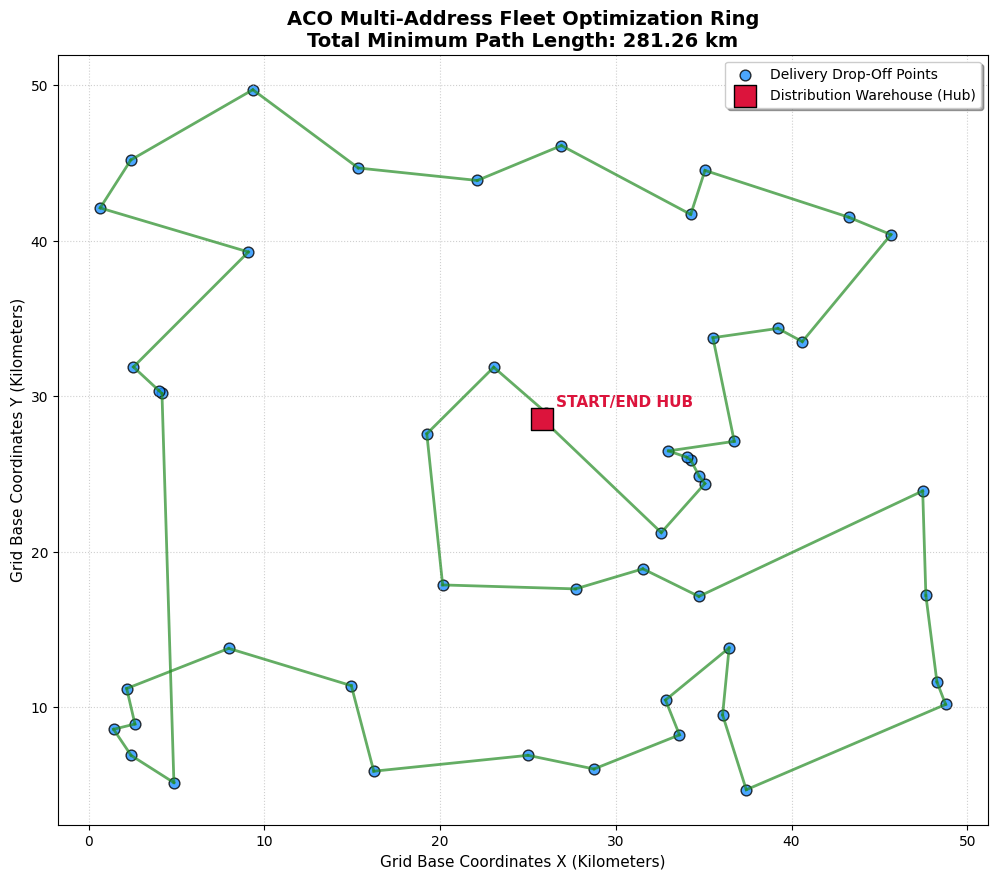

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

# =====================================================================
# 1. GENERATE THE 50-DELIVERY REGION & WAREHOUSE
# =====================================================================
np.random.seed(101)  # Fixed seed ensures identical node generation
num_addresses = 50
num_nodes = num_addresses + 1 # 1 Warehouse (Index 0) + 50 Residential Drops

# Create coordinates in a 50 km x 50 km delivery zone
# Node 0 is structurally designated as the local E-commerce fulfillment hub
locations = np.random.rand(num_nodes, 2) * 50

# Compute standard Euclidean distance matrix across all points
distance_matrix = cdist(locations, locations, metric='euclidean')
distance_matrix[distance_matrix == 0] = 1e-10  # Protection wrapper against zero division

# =====================================================================
# 2. HYPERPARAMETER CALIBRATION FOR SCALED PROBABILITY
# =====================================================================
num_ants = 30          # Increased scout size to comprehensively cover 50 nodes
num_iterations = 100   # Iteration limit to enforce path convergence
alpha = 1.0            # Pheromone structural weighting parameter
beta = 3.0             # Heuristic distance priority weight (high value favors short gaps)
evaporation_rate = 0.4 # Pheromone trail decay rate per run loop (40%)
Q = 100                # Base mathematical constant scaling pheromone deployment

# Setup matrix matrices
pheromones = np.ones((num_nodes, num_nodes))
visibility = 1.0 / distance_matrix

best_distance = float('inf')
best_route = []

# =====================================================================
# 3. ACO OPTIMIZATION SIMULATION ENGINE
# =====================================================================
print(f"Deploying {num_ants} ants to map optimized route structures for {num_addresses} deliveries...")

for iteration in range(num_iterations):
    all_ant_routes = []
    all_ant_distances = []

    for ant in range(num_ants):
        current_node = 0  # Start engine at the primary E-commerce Warehouse
        visited = [current_node]
        unvisited = list(range(1, num_nodes))

        while unvisited:
            # Vectorised structural probability assessment
            pheromone_vals = pheromones[current_node, unvisited] ** alpha
            visibility_vals = visibility[current_node, unvisited] ** beta
            probabilities = pheromone_vals * visibility_vals

            probabilities /= np.sum(probabilities) # Enforce strict probability range normalization

            # Roulette selection matrix execution
            next_node = np.random.choice(unvisited, p=probabilities)
            visited.append(next_node)
            unvisited.remove(next_node)
            current_node = next_node

        visited.append(0) # Route loop back configuration to the hub

        # Calculate standard loop summation
        route_distance = sum(distance_matrix[visited[i], visited[i+1]] for i in range(num_nodes))

        all_ant_routes.append(visited)
        all_ant_distances.append(route_distance)

        # Track global performance milestones
        if route_distance < best_distance:
            best_distance = route_distance
            best_route = visited

    # Decay trails uniformly across network
    pheromones *= (1.0 - evaporation_rate)

    # Lay down brand new pheromone values weighted against performance metrics
    for route, dist in zip(all_ant_routes, all_ant_distances):
        for i in range(num_nodes):
            from_node = route[i]
            to_node = route[i+1]
            # Inverse-proportional layout: Shorter trips leave significantly stronger trails
            pheromones[from_node, to_node] += Q / dist
            pheromones[to_node, from_node] += Q / dist

    if (iteration + 1) % 20 == 0 or iteration == 0:
        print(f"Iteration {iteration + 1:3d}/{num_iterations} | Global Best Loop: {best_distance:.2f} km")

# =====================================================================
# 4. DATA VISUALIZATION OUTPUT MATRICES
# =====================================================================
print("\n" + "="*40 + "\nLAST-MILE ROUTE ANALYSIS COMPLETED\n" + "="*40)
print(f"Optimized Sequencing Flow:\n{best_route}\n")
print(f"Minimized Round-Trip Fleet Distance: {best_distance:.2f} km")

# Construct geographic mapping layout
plt.figure(figsize=(12, 10))

# Scatter drop destinations
plt.scatter(locations[1:, 0], locations[1:, 1], color='dodgerblue', s=60, edgecolors='black', alpha=0.8, label='Delivery Drop-Off Points')
# Highlight Warehouse Core Node
plt.scatter(locations[0, 0], locations[0, 1], color='crimson', marker='s', s=250, edgecolors='black', zorder=5, label='Distribution Warehouse (Hub)')

# Map optimization trajectory vector paths
for i in range(len(best_route) - 1):
    start_pos = locations[best_route[i]]
    end_pos = locations[best_route[i+1]]
    plt.plot([start_pos[0], end_pos[0]], [start_pos[1], end_pos[1]], color='forestgreen', linestyle='-', linewidth=2, alpha=0.7)

# Add minor text offsets for clarity index positioning
plt.text(locations[0, 0] + 0.8, locations[0, 1] + 0.8, 'START/END HUB', color='crimson', fontsize=11, fontweight='bold')

plt.title(f'ACO Multi-Address Fleet Optimization Ring\nTotal Minimum Path Length: {best_distance:.2f} km', fontsize=14, fontweight='bold')
plt.xlabel('Grid Base Coordinates X (Kilometers)', fontsize=11)
plt.ylabel('Grid Base Coordinates Y (Kilometers)', fontsize=11)
plt.legend(loc='upper right', shadow=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()
